# Mini-Project 1: Fetching and Displaying a Weather Forecast with Python Web APIs

**Course:** MSCS & MSDS OOP with Python, Assignment 2 (Advent 2026)

This notebook takes a place name, finds its coordinates with the **Open-Meteo Geocoding API**, requests a daily
forecast from the **Open-Meteo Forecast API**, and displays it as a table, a chart and a text summary. A second
source, **MET Norway Locationforecast 2.0**, is used for comparison in Part C.

Reusable code lives in `src/weather/` and is imported here:

| Module | Responsibility |
|---|---|
| `weather.http` | `fetch_json()`: timeout, `raise_for_status()`, retries with exponential backoff, custom `WeatherAPIError` |
| `weather.geocoding` | `geocode()`, `choose_location()`, `Location` data class |
| `weather.forecast` | `get_forecast()`, `forecast_to_dataframe()`, WMO code mapping, `summarise()` |
| `weather.metno` | MET Norway client, User-Agent/contact handling, hourly → daily aggregation |
| `weather.config` | Contact email and the User-Agent sent with every request |
| `weather.simulate` | Simulated failures (flaky server, no network) for the Part C demonstrations |
| `weather.plotting` | Charts |

Offline tests (`tests/test_weather.py`) use saved JSON in `tests/fixtures/weather/`.

**Data sources:** Weather data by [Open-Meteo.com](https://open-meteo.com/) (CC BY 4.0) and
[MET Norway](https://api.met.no/) (CC BY 4.0). Geocoding data from GeoNames via Open-Meteo (CC BY 4.0).

## Configuration

This is the **only cell you need to edit**. The contact email is read from the `CONTACT_EMAIL` environment
variable, so no real address is stored in the notebook. It is sent in the `User-Agent` of **every** request, as the
brief requires. If it is not set, a warning is printed, Open-Meteo is called with the application name only, and the
MET Norway call is replaced by a saved sample, so the notebook still runs from top to bottom.

In [1]:
import os

LOCATION = "Dresden"        # place name to look up
LOCATION_CHOICE = 0         # which candidate to use when several places match (0 = most relevant)
INTERACTIVE = False         # True: list the candidates and ask with input() instead
FORECAST_DAYS = 7           # 1-16
CONTACT_EMAIL = os.environ.get("CONTACT_EMAIL", "your.name@university.example")  # placeholder, never commit a real one

In [2]:
import json
import logging
import time
import urllib.parse
import urllib.request
from dataclasses import asdict
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display

from weather import (
    AmbiguousLocationError, ConfigurationError, LocationNotFoundError, RetryPolicy, choose_location,
    contact_email, fetch_json, forecast_to_dataframe, geocode, get_forecast, get_metno_forecast,
    metno_to_daily, summarise, user_agent,
)
from weather.plotting import plot_comparison, plot_forecast
from weather.simulate import FlakySession, OfflineSession, run_demo

rng = np.random.default_rng(2026)  # reproducibility: no random steps here, but the seed is fixed as required
logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s", force=True)
pd.set_option("display.width", 120)
FIXTURES = Path("tests/fixtures/weather")

**Libraries outside the brief's allowed list, with a one-line justification each.** The allowed list is urllib,
requests, json, datetime, time, os, pandas and matplotlib.

| Library | Justification |
|---|---|
| `numpy` | The brief requires a seeded `np.random.default_rng(seed)`; it is already a pandas dependency. |
| `logging` (stdlib) | Makes each retry attempt visible as a warning without `print` calls inside library code. |
| `dataclasses` (stdlib) | `Location` is a frozen dataclass; `asdict` turns candidates into a table. |
| `functools.partial` (stdlib) | Pre-configures `fetch_json` (User-Agent, simulated session, timeout) for the demos. |
| `pathlib` (stdlib) | Portable paths to the saved JSON samples. |
| `re` (stdlib, in `weather.config`) | Validates the format of the contact email. |
| `collections.abc`, `typing` (stdlib, in `src/`) | Type hints only. |
| `subprocess`, `sys` (stdlib) | Run the offline `pytest` suite from the notebook with the same interpreter. |
| `IPython.display` | Shows a table in the middle of a cell. It ships with Jupyter. |
| `jinja2` | Required by pandas `Styler` for the formatted forecast table. |

### Identifying ourselves: User-Agent with the contact email

In [3]:
try:
    USER_AGENT = user_agent(contact_email(CONTACT_EMAIL))
except ConfigurationError as exc:
    USER_AGENT = user_agent(None)
    print(f"WARNING: {exc}. Requests will identify the application only.")
print("User-Agent:", USER_AGENT.replace(CONTACT_EMAIL, "<contact email>"))

fetch = partial(fetch_json, headers={"User-Agent": USER_AGENT})  # every Part B/C request goes through this

User-Agent: advent2026-weather-coursework/1.0 (<contact email>)


---
## Part A: HTTP fundamentals

### A1. Geocoding with the standard library only (`urllib.request`, `urllib.parse`, `json`)

In [4]:
GEOCODING_URL = "https://geocoding-api.open-meteo.com/v1/search"

query = urllib.parse.urlencode({"name": LOCATION, "count": 3, "language": "en", "format": "json"})
url = f"{GEOCODING_URL}?{query}"
request = urllib.request.Request(url, headers={"User-Agent": USER_AGENT})

with urllib.request.urlopen(request, timeout=10) as response:
    charset = response.headers.get_content_charset() or "utf-8"   # decode bytes ourselves
    urllib_payload = json.loads(response.read().decode(charset))

print("Request URL:", url)
for r in urllib_payload.get("results", []):
    print(f"  {r['name']}, {r.get('admin1', '')}, {r.get('country', '')}: {r['latitude']:.4f}, {r['longitude']:.4f}")

Request URL: https://geocoding-api.open-meteo.com/v1/search?name=Dresden&count=3&language=en&format=json
  Dresden, Saxony, Germany: 51.0509, 13.7383
  Dresden, Tennessee, United States: 36.2914, -88.7081
  Dresden, Ohio, United States: 40.1215, -82.0107


### A2. The same request with `requests` (using `params=` and a timeout)

In [5]:
response = requests.get(
    GEOCODING_URL,
    params={"name": LOCATION, "count": 3, "language": "en", "format": "json"},
    headers={"User-Agent": USER_AGENT},
    timeout=10,
)
response.raise_for_status()
requests_payload = response.json()

print("Request URL:", response.url)
same = [r["id"] for r in requests_payload["results"]] == [r["id"] for r in urllib_payload["results"]]
print("Same results as urllib:", same)

Request URL: https://geocoding-api.open-meteo.com/v1/search?name=Dresden&count=3&language=en&format=json
Same results as urllib: True


### A3. Comparing the two approaches

| Aspect | `urllib` (standard library) | `requests` |
|---|---|---|
| **Code length** | Longer: build the query string with `urlencode`, create a `Request`, open it with a context manager, read bytes, decode, then `json.loads`. | Shorter: one `requests.get(url, params=..., timeout=...)` call, then `.json()`. |
| **Error handling** | `urlopen` raises `HTTPError` for 4xx/5xx and `URLError` for network problems. Reading the error body needs extra code (`err.read()`). There are no built-in retries. | Status errors are raised only when you call `raise_for_status()`, so you choose when. There is a clear hierarchy (`ConnectionError`, `Timeout`, `HTTPError`, all `RequestException`). Retries are possible through `HTTPAdapter`. The response object stays available for inspection. |
| **Headers** | Set through the `Request(headers=...)` object; reading response headers via `response.headers` (an `email.message.Message`). | `headers=` keyword argument; `response.headers` is a case-insensitive dict. |
| **Encoding** | Manual: you must read the charset from `Content-Type` and decode the bytes yourself. The query string must be encoded explicitly with `urlencode`. | Automatic: `params=` is URL-encoded, `.text` decodes using the detected charset, and `.json()` parses. You can still override `response.encoding`. |
| **Other** | No dependency, which suits scripts that must run anywhere. | Third-party dependency, but sessions (connection reuse), cookies, timing (`response.elapsed`) and testability are much better. |

For this project, `requests` is the better tool. `urllib` is shown only because it shows what `requests`
automates.

### A4. Status code, `Content-Type` and response time for one request

In [6]:
start = time.perf_counter()
response = requests.get(
    GEOCODING_URL, params={"name": LOCATION, "count": 1, "format": "json"},
    headers={"User-Agent": USER_AGENT}, timeout=10,
)
wall_clock_ms = (time.perf_counter() - start) * 1000

pd.Series({
    "URL": response.url,
    "Status code": f"{response.status_code} {response.reason}",
    "Content-Type": response.headers.get("Content-Type"),
    "Encoding used by requests": response.encoding,
    "Time to response headers (response.elapsed)": f"{response.elapsed.total_seconds() * 1000:.0f} ms",
    "Wall-clock time incl. body (perf_counter)": f"{wall_clock_ms:.0f} ms",
    "Body size": f"{len(response.content)} bytes",
}, name="Value").to_frame()

,Value
URL,https://geocoding-api.open-meteo.com/v1/search...
Status code,200 OK
Content-Type,application/json; charset=utf-8
Encoding used by requests,utf-8
Time to response headers (response.elapsed),765 ms
Wall-clock time incl. body (perf_counter),767 ms
Body size,397 bytes


`response.elapsed` measures the time from sending the request until the response headers were parsed. The
`perf_counter` time also includes reading the body and connection setup. Both depend heavily on the network, so they
change on every run.

---
## Part B: Forecast retrieval and display

### B1. `geocode(name)`: candidates, zero results and ambiguous names

`geocode()` (in `src/weather/geocoding.py`) goes through the robust `fetch_json()` helper and returns a list of
`Location` objects. When nothing matches, the API **omits the `results` key entirely**, so the parser uses
`payload.get("results")` and `geocode()` raises `LocationNotFoundError`. When several places match,
`choose_location()` either uses the configured index, asks interactively, or raises `AmbiguousLocationError` listing
the candidates.

In [7]:
candidates = geocode(LOCATION, fetch=fetch)
display(pd.DataFrame([asdict(c) for c in candidates]).head(5))

location = choose_location(candidates, None if INTERACTIVE else LOCATION_CHOICE, interactive=INTERACTIVE)
print("Selected:", location.label, "| time zone:", location.timezone)

,name,latitude,longitude,country,admin1,timezone,population,elevation
0,Dresden,51.05089,13.73832,Germany,Saxony,Europe/Berlin,556227.0,116.0
1,Dresden,36.29145,-88.70811,United States,Tennessee,America/Chicago,2898.0,130.0
2,Dresden,40.12146,-82.01069,United States,Ohio,America/New_York,1706.0,226.0
3,Dresden,42.68396,-76.95580,United States,New York,America/New_York,300.0,155.0
4,Dresden,39.62417,-100.42236,United States,Kansas,America/Chicago,41.0,833.0


Selected: Dresden, Saxony, Germany (51.05, 13.74) | time zone: Europe/Berlin


In [8]:
# Ambiguous name: without a choice, the candidates are listed in the exception.
springfields = geocode("Springfield", fetch=fetch)
try:
    choose_location(springfields)
except AmbiguousLocationError as exc:
    print(f"{type(exc).__name__}: {len(exc.candidates)} candidates")
    for i, c in enumerate(exc.candidates):
        print(f"  [{i}] {c.label}  population={c.population}")

picked = choose_location(springfields, 1)  # e.g. the user picks [1]
print("\nPicked:", picked.label)

# Zero results: the 'results' key is absent.
try:
    geocode("Xqzzyplat", fetch=fetch)
except LocationNotFoundError as exc:
    print(f"\n{type(exc).__name__}: {exc}")

AmbiguousLocationError: 10 candidates
  [0] Springfield, Missouri, United States (37.22, -93.30)  population=170188
  [1] Springfield, Illinois, United States (39.80, -89.64)  population=114394
  [2] Springfield, Massachusetts, United States (42.10, -72.59)  population=154341
  [3] Springfield, Ohio, United States (39.92, -83.81)  population=59680
  [4] Springfield, Tennessee, United States (36.51, -86.89)  population=16808
  [5] Palmyra, Missouri, United States (39.79, -91.52)  population=3616
  [6] Jackson, Minnesota, United States (43.62, -94.99)  population=3234
  [7] Springfield, Kentucky, United States (37.69, -85.22)  population=3055
  [8] Springfield, Georgia, United States (32.37, -81.31)  population=2889
  [9] Springfield, Colorado, United States (37.41, -102.61)  population=1396

Picked: Springfield, Illinois, United States (39.80, -89.64)



LocationNotFoundError: No place found for 'Xqzzyplat'


Note that the geocoder also returns places that only match an *alternative* name: for example, Palmyra and Jackson
appear among the "Springfield" candidates. This is why the user must be shown the full label (region, country,
coordinates) before choosing.

### B2. `get_forecast(lat, lon, days)`

The request asks for daily maximum and minimum temperature, precipitation sum, maximum wind speed and the weather code.
`timezone=auto` makes Open-Meteo resolve the location's own time zone, so each date is a *local* calendar day.

In [9]:
payload = get_forecast(location.latitude, location.longitude, FORECAST_DAYS, fetch=fetch)
print("Time zone:", payload["timezone"], f"(UTC offset {payload['utc_offset_seconds'] / 3600:+.0f} h)")
print("Units:", payload["daily_units"])

Time zone: Europe/Berlin (UTC offset +2 h)
Units: {'time': 'iso8601', 'weather_code': 'wmo code', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm', 'wind_speed_10m_max': 'km/h'}


### B3. JSON → pandas DataFrame with units and decoded weather codes

In [10]:
forecast = forecast_to_dataframe(payload)
forecast.dtypes.to_frame("dtype")

,dtype
Weather,str
Max temp (°C),float64
Min temp (°C),float64
Precipitation (mm),float64
Max wind (km/h),float64
Weather code,Int64


### B4. Display: text summary, formatted table and chart

In [11]:
print(summarise(forecast, location))

Forecast for Dresden, Saxony, Germany (51.05, 13.74), Fri 16 Oct to Thu 22 Oct: highs 10 to 19 °C, lows 6 to 10 °C. 0 of 7 days with at least 1 mm of rain; wettest Thu 22 Oct (0.3 mm). Windiest Tue 20 Oct (13 km/h). Most common conditions: overcast. Data: Open-Meteo.com (CC BY 4.0).


In [12]:
(forecast.drop(columns="Weather code")
    .rename_axis(f"Date ({payload['timezone']})")
    .style.format({"Max temp (°C)": "{:.1f}", "Min temp (°C)": "{:.1f}",
                   "Precipitation (mm)": "{:.1f}", "Max wind (km/h)": "{:.0f}"})
    .format_index(lambda d: d.strftime("%a %d %b %Y"))
    .background_gradient(subset=["Max temp (°C)"], cmap="Reds")
    .bar(subset=["Precipitation (mm)"], color="#7fb7be", vmin=0)
    .set_caption(f"Daily forecast for {location.label}. Source: Open-Meteo.com (CC BY 4.0)"))

,Weather,Max temp (°C),Min temp (°C),Precipitation (mm),Max wind (km/h)
Date (Europe/Berlin),,,,,
Fri 16 Oct 2026,Overcast,18.7,6.2,0.0,7
Sat 17 Oct 2026,Slight rain,16.0,9.6,0.1,12
Sun 18 Oct 2026,Fog,12.8,8.5,0.0,7
Mon 19 Oct 2026,Overcast,10.4,5.8,0.0,10
Tue 20 Oct 2026,Overcast,14.0,7.4,0.0,13
Wed 21 Oct 2026,Overcast,14.6,9.6,0.0,12
Thu 22 Oct 2026,Slight rain,12.8,9.5,0.3,12


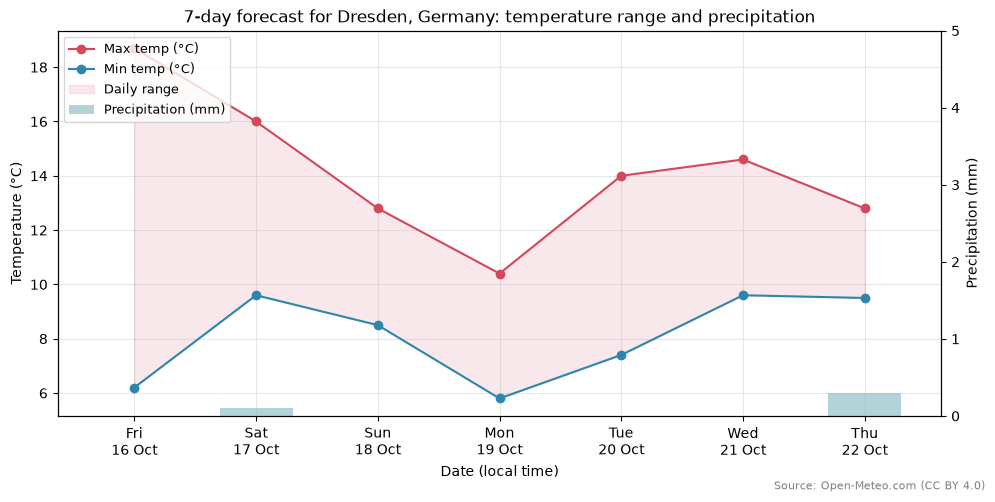

In [13]:
fig = plot_forecast(forecast, f"{FORECAST_DAYS}-day forecast for {location.name}, {location.country}: "
                              "temperature range and precipitation")
plt.show()

---
## Part C: Robustness and a second source

### C1. One wrapper for every request

Every request in Parts B and C goes through `fetch_json()` (in `src/weather/http.py`), which:

* sets a **timeout** on every attempt (default 10 s);
* calls **`raise_for_status()`**;
* **retries** connection errors, timeouts, HTTP 429 and 5xx responses with **exponential backoff**
  (`0.5 s, 1 s, 2 s, ...`, capped by `RetryPolicy.backoff_cap`) and a **retry cap** (`max_attempts`);
* does **not** retry other 4xx errors (the input is wrong, so retrying cannot help) and passes on the server's
  `reason` text;
* raises a custom **`WeatherAPIError`** (with URL, attempts, status and reason, chained to the original exception)
  when it finally fails.

The demonstrations below use a short backoff so the notebook stays fast. Retry attempts are logged as warnings.
`FlakySession` (simulated 503s) and `OfflineSession` (simulated loss of network) are in `src/weather/simulate.py`.

In [14]:
FAST = RetryPolicy(max_attempts=3, backoff_base=0.2, backoff_cap=1.0)

flaky = FlakySession(failures=2)  # see src/weather/simulate.py
print(run_demo("Transient 503 twice, then success",
               lambda: fetch(GEOCODING_URL, {"name": LOCATION, "count": 1}, session=flaky, policy=FAST)))
print("Attempts made:", flaky.calls)

WARNING weather.http: Attempt 1/3 for https://geocoding-api.open-meteo.com/v1/search failed: 503 Server Error: Service Unavailable for url: https://geocoding-api.open-meteo.com/v1/search


WARNING weather.http: Attempt 2/3 for https://geocoding-api.open-meteo.com/v1/search failed: 503 Server Error: Service Unavailable for url: https://geocoding-api.open-meteo.com/v1/search


Transient 503 twice, then success
    OK -> dict
    (1.46 s)

Attempts made: 3


### C2. Deliberately broken inputs

In [15]:
lat, lon = location.latitude, location.longitude
offline_fetch = partial(fetch, session=OfflineSession(), policy=FAST)
tiny_timeout_fetch = partial(fetch, timeout=0.001, policy=FAST)

print(run_demo("1. Invalid city name", lambda: geocode("Xqzzyplat", fetch=fetch)))
print(run_demo("2a. Invalid latitude, caught locally", lambda: get_forecast(999, lon, fetch=fetch)))
print(run_demo("2b. Invalid latitude sent to the server (400, not retried)",
               lambda: get_forecast(999, lon, validate=False, fetch=fetch)))
print(run_demo("3. No network (simulated)", lambda: get_forecast(lat, lon, fetch=offline_fetch)))
print(run_demo("4. Tiny timeout (1 ms)", lambda: get_forecast(lat, lon, fetch=tiny_timeout_fetch)))

1. Invalid city name
    LocationNotFoundError: No place found for 'Xqzzyplat'
    (0.78 s)

2a. Invalid latitude, caught locally
    InvalidCoordinatesError: Latitude must be in [-90, 90], got 999
    (0.00 s)



WARNING weather.http: Attempt 1/4 for https://api.open-meteo.com/v1/forecast failed: 503 Server Error: Service Unavailable for url: https://api.open-meteo.com/v1/forecast?latitude=999&longitude=13.73832&daily=weather_code%2Ctemperature_2m_max...


WARNING weather.http: Attempt 1/3 for https://api.open-meteo.com/v1/forecast failed: Simulated: network is unreachable


2b. Invalid latitude sent to the server (400, not retried)
    WeatherAPIError: Request rejected (url=https://api.open-meteo.com/v1/forecast, attempts=2, status=400, reason='Latitude must be in range of -90 to 90°. Given: 999.0.')
    (1.41 s)



WARNING weather.http: Attempt 2/3 for https://api.open-meteo.com/v1/forecast failed: Simulated: network is unreachable


...

WARNING weather.http: Attempt 1/3 for https://api.open-meteo.com/v1/forecast failed: HTTPSConnectionPool(host='api.open-meteo.com', port=443): Max retries exceeded with url: /v1/forecast?latitude=51.05089&longitude=13.73832&daily=weather_code...


3. No network (simulated)
    WeatherAPIError: Giving up after 3 attempts: ConnectionError (url=https://api.open-meteo.com/v1/forecast, attempts=3, reason='Simulated: network is unreachable')
    (0.61 s)



WARNING weather.http: Attempt 2/3 for https://api.open-meteo.com/v1/forecast failed: HTTPSConnectionPool(host='api.open-meteo.com', port=443): Max retries exceeded with url: /v1/forecast?latitude=51.05089&longitude=13.73832&daily=weather_code...


WARNING weather.http: Attempt 3/3 for https://api.open-meteo.com/v1/forecast failed: HTTPSConnectionPool(host='api.open-meteo.com', port=443): Max retries exceeded with url: /v1/forecast?latitude=51.05089&longitude=13.73832&daily=weather_code...


4. Tiny timeout (1 ms)
    WeatherAPIError: Giving up after 3 attempts: ConnectTimeout (url=https://api.open-meteo.com/v1/forecast, attempts=3, reason="HTTPSConnectionPool(host='api.open-meteo.com', port=443): Max retries exceeded with url: /v1/forecast?latitude=51.05089&longitude=13.73832&daily=weather_code...")
    (0.64 s)



Each failure produces one clear exception type the caller can handle: `LocationNotFoundError`,
`InvalidCoordinatesError`, or `WeatherAPIError` with the status code and the server's reason. Nothing fails silently,
and errors that cannot be fixed by retrying (400 Bad Request) fail on the first attempt.

### C3. Second source: MET Norway Locationforecast 2.0

MET Norway requires an identifying `User-Agent` with contact details (here: the app name plus `CONTACT_EMAIL`)
and asks clients to send at most four decimals of latitude and longitude. The response is a time series. It is
hourly for roughly the first 2–3 days and 6-hourly after that, in UTC. `metno_to_daily()` converts it to the
location's time zone and aggregates it to daily max/min temperature, precipitation and maximum wind, with wind
converted from m/s to km/h.

In [16]:
try:
    email = contact_email(CONTACT_EMAIL)
    met_payload = get_metno_forecast(location.latitude, location.longitude, email)
    comparison_location, om_frame, tz = location.label, forecast, payload["timezone"]
    print("MET Norway: live data,", met_payload["properties"]["meta"]["updated_at"])
except ConfigurationError as exc:
    # Without a contact address we must not call MET Norway; fall back to the saved Dresden samples.
    print(f"{exc}\n-> Using saved samples for Dresden from {FIXTURES}/ instead.")
    met_payload = json.loads((FIXTURES / "metno_dresden.json").read_text(encoding="utf-8"))
    sample = json.loads((FIXTURES / "forecast_dresden.json").read_text(encoding="utf-8"))
    comparison_location, om_frame, tz = "Dresden (saved sample)", forecast_to_dataframe(sample), sample["timezone"]

met_daily = metno_to_daily(met_payload, tz)
met_daily.round(1)

MET Norway: live data, 2026-10-16T07:18:51Z


,Max temp (°C),Min temp (°C),Precipitation (mm),Max wind (km/h),Data points
Date,,,,,
2026-10-16,17.8,7.9,0.0,11.9,15
2026-10-17,13.1,9.2,4.7,16.6,24
2026-10-18,11.9,7.6,0.0,12.2,24
2026-10-19,11.0,5.9,0.0,13.7,6
2026-10-20,14.4,4.3,0.0,14.4,4
2026-10-21,14.1,8.3,0.1,15.5,4
2026-10-22,13.1,8.0,5.3,12.6,4
2026-10-23,11.7,4.3,0.0,6.8,4
2026-10-24,13.7,3.4,0.2,13.0,4


In [17]:
cols = ["Max temp (°C)", "Min temp (°C)", "Precipitation (mm)", "Max wind (km/h)"]
common = om_frame.index.intersection(met_daily.index)
comparison = pd.concat(
    {"Open-Meteo": om_frame.loc[common, cols], "MET Norway": met_daily.loc[common, cols]}, axis=1
)
for col in cols:
    comparison[("Difference (MET − OM)", col)] = comparison[("MET Norway", col)] - comparison[("Open-Meteo", col)]
display(comparison.round(1))

print("Mean absolute difference over", len(common), "days:")
print(comparison["Difference (MET − OM)"].abs().mean().round(2).to_string())

Open-Meteo                                                     MET Norway                \
           Max temp (°C) Min temp (°C) Precipitation (mm) Max wind (km/h) Max temp (°C) Min temp (°C)   
Date                                                                                                    
2026-10-16          18.7           6.2                0.0             6.6          17.8           7.9   
2026-10-17          16.0           9.6                0.1            12.1          13.1           9.2   
2026-10-18          12.8           8.5                0.0             7.3          11.9           7.6   
2026-10-19          10.4           5.8                0.0             9.5          11.0           5.9   
2026-10-20          14.0           7.4                0.0            12.8          14.4           4.3   
2026-10-21          14.6           9.6                0.0            12.1          14.1           8.3   
2026-10-22          12.8           9.5                0.3            12.3          13.1           8.0   

                                              Difference (MET − OM)                                                   
           Precipitation (mm) Max wind (km/h)         Max temp (°C) Min temp (°C) Precipitation (mm) Max wind (km/h)  
Date                                                                                                                  
2026-10-16                0.0            11.9                  -0.9           1.7                0.0             5.3  
2026-10-17                4.7            16.6                  -2.9          -0.4                4.6             4.5  
2026-10-18                0.0            12.2                  -0.9          -0.9                0.0             4.9  
2026-10-19                0.0            13.7                   0.6           0.1                0.0             4.2  
2026-10-20                0.0            14.4                   0.4          -3.1                0.0             1.6  
2026-10-21                0.1            15.5                  -0.5          -1.3                0.1             3.4  
2026-10-22                5.3            12.6                   0.3          -1.5                5.0             0.3

Mean absolute difference over 7 days:
Max temp (°C)         0.93
Min temp (°C)         1.29
Precipitation (mm)    1.39
Max wind (km/h)       3.45


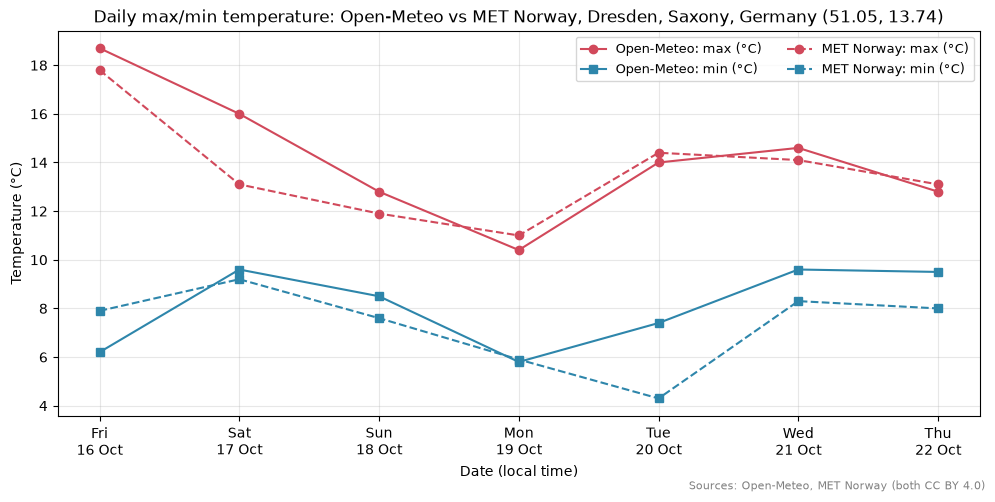

In [18]:
fig = plot_comparison(om_frame.loc[common], met_daily.loc[common], ("Open-Meteo", "MET Norway"),
                      f"Daily max/min temperature: Open-Meteo vs MET Norway, {comparison_location}")
plt.show()

The two sources usually agree within a degree or two on temperature. Larger differences are expected for
(i) the **first day**, which MET Norway covers only from the current hour onwards, and (ii) days in the **6-hourly
part** of the MET series, where max/min come from only four instantaneous samples and so understate the true
extremes. Open-Meteo's daily max/min are derived from hourly model output. Precipitation and wind differ more
because the two services use different models and definitions (MET's wind is the 10 m mean at each step, not a
daily peak).

---
## Offline tests

The parsing and robustness functions are tested offline with saved JSON (`pytest tests/test_weather.py`).

In [19]:
import subprocess, sys
result = subprocess.run([sys.executable, "-m", "pytest", "tests/test_weather.py", "-q", "--color=no"],
                        capture_output=True, text=True)
print(result.stdout[-1500:] or result.stderr[-1500:])

...............                                                          [100%]



---
## Part D: Report

### 1. Data flow from user input to displayed forecast

```
 Config cell                      src/weather                                   External services
 ───────────                      ───────────                                   ─────────────────
 LOCATION ──► geocode(name) ──► fetch_json() ──HTTPS GET ?name=…──────────►  Open-Meteo Geocoding
                  │                 ▲ timeout · raise_for_status ·            (GeoNames data)
                  │                 │ retry+backoff · WeatherAPIError
                  ▼                 │
          parse_locations() ◄──── JSON (results may be absent)
                  │
                  ▼
          choose_location()  ── ambiguous? → list candidates → user's choice (config / input())
                  │ Location(lat, lon, tz)
                  ▼
          get_forecast() ──► validate ──► fetch_json() ──HTTPS GET ?latitude…──►  Open-Meteo Forecast
                  │                                    ──HTTPS GET ?lat…&lon…──►  MET Norway (User-Agent + email)
                  ▼
          forecast_to_dataframe()  (units from daily_units, WMO code → text)
          metno_to_daily()         (UTC → local time, hourly/6-hourly → daily, m/s → km/h)
                  │ pandas DataFrame
                  ▼
          summarise()  ·  Styler table  ·  plot_forecast() / plot_comparison()   ──►  Notebook output
```

The user supplies a place name in the configuration cell. `geocode()` sends it to the Open-Meteo Geocoding API
through `fetch_json()`, the single wrapper that applies timeouts, status checks and retries to every request. The JSON
reply is converted into `Location` objects. If the name is ambiguous, the candidates are listed with region,
country and coordinates, and one is chosen from configuration (or interactively). The chosen latitude and longitude
are validated and sent to the Forecast API with `timezone=auto`, so the daily values refer to local calendar days.
The response is reshaped into a pandas DataFrame whose column names carry units taken from the API's own
`daily_units` block, and weather codes are decoded using the WMO table from the Open-Meteo documentation. Finally the
DataFrame feeds three views: a text summary, a formatted table and a chart. In Part C the same coordinates are sent
to MET Norway, whose hourly UTC time series is aggregated to local daily values and compared with Open-Meteo.

### 2. Licensing and usage terms, and what they mean for a real product

**Open-Meteo (geocoding and forecast).** The free API needs no key, but its terms (OpenMeteo GmbH, Switzerland)
restrict it to *non-commercial* use: fewer than 10,000 calls a day, 5,000 an hour and 600 a minute. Public
research and educational use count as non-commercial. Websites or apps with subscriptions or advertising, and
integration into commercial products, count as commercial. The data are licensed under **CC BY 4.0**, so any
display must credit Open-Meteo (and, for geocoding, GeoNames). A commercial product needs a paid subscription with
an API key. The free tier comes with no availability guarantee. For a
real product this means budgeting for the commercial plan, keeping the attribution visible in the user interface
(this notebook prints it in the summary, the table caption and the chart), and caching responses so that one
popular city does not cost thousands of identical calls.

**MET Norway Locationforecast 2.0.** The open data are licensed under **CC BY 4.0** and must be attributed to MET
Norway. The *terms of service* add operational rules. Every request must carry a `User-Agent` that identifies the
application and gives contact details (a missing or generic agent can be blocked with **403 Forbidden**).
Anything over 20 requests/second per application (in total, not per client) needs a special agreement, and
throttled clients receive **429**. Clients must not repeat a request before the time in the `Expires` header,
should use `If-Modified-Since` with the previous `Last-Modified` value, and must truncate coordinates to four
decimals (newer products reject five or more with 403). Deliberate abuse leads to a permanent ban, and there is
no service-level guarantee. In a product, MET Norway calls would go through a
backend proxy that caches by rounded coordinates, so that end users' devices never call the API directly. The
operator's contact address would come from server configuration, never from source code, which is why this
notebook reads it from an environment variable.

### 3. Reliability issues met, and how the code handles them

* **Missing keys instead of empty lists.** For an unknown name the geocoder returns `{"generationtime_ms": …}` with
  no `results` key. A naive `payload["results"]` raises `KeyError`. The parser uses `.get()` and `geocode()`
  raises a meaningful `LocationNotFoundError`.
* **Ambiguous and surprising matches.** "Springfield" returns ten places, and the list includes towns that match
  only an alternative name. The code never guesses: it lists the candidates with region, country and coordinates
  and requires an explicit choice.
* **Invalid input.** An out-of-range latitude produces HTTP 400 with a JSON `reason`. Inputs are validated locally
  first. If a bad value still reaches the server, the 400 is *not* retried, and its reason appears in the
  exception message.
* **Network failures and slow responses.** Connection errors, timeouts, rate limiting (429) and 5xx responses are
  transient, so they are retried with exponential backoff and a cap. After the last attempt a single
  `WeatherAPIError` is raised, chained to the original exception for debugging. This was not hypothetical: while
  the test samples were being captured (`scripts/capture_fixtures.py`, 16 October 2026), the Forecast API answered
  **503 Service Unavailable three times in a row**, and the wrapper recovered on the fourth attempt after waiting
  0.5, 1 and 2 seconds. Tests prove the behaviour with fake sessions (503, 503, 200 succeeds after three calls; a
  400 stops after one).
* **Time zones and partial days.** Open-Meteo returns local dates only when `timezone` is set. MET Norway always
  returns UTC. Its first day is partial, and after about 60 hours the series becomes 6-hourly, where the
  1-hour precipitation field disappears. `metno_to_daily()` converts to local time, switches to the 6-hour amounts
  where needed (so no rain is double-counted), and drops an incomplete first day.
* **Different units.** MET Norway reports wind in m/s and Open-Meteo in km/h. Units are carried in column names and
  converted explicitly.
* **Reproducibility versus live data.** Forecasts change hourly, so tests use saved JSON fixtures and run offline.
  The notebook falls back to a saved MET sample when no contact email is configured, so *Restart & Run All*
  always completes.

### 4. Privacy implications of sending location queries to third parties

A place name or a coordinate pair is personal data when it can be linked to a person. Every query in this
project sends the location in the URL's query string, together with the caller's **IP address** and the
`User-Agent`. URLs are routinely written to server logs, proxies and analytics systems. A series of forecast
requests from one IP address can reveal where someone lives, works or travels. Combined with timing, it can
reveal routines (for example, a daily request for the same coordinates at 07:00). Precise GPS coordinates are
far more revealing than a city name. Both providers state that they process requests only to deliver the service,
but the data still leave the user's control and cross borders (Open-Meteo is operated from Switzerland, MET Norway
from Norway). Open-Meteo's terms state that free-API web-server logs, which may contain the requested coordinates,
are kept for up to 90 days.

For a real product, this triggers obligations under laws such as the EU GDPR and Uganda's **Data Protection and
Privacy Act, 2019**: a lawful basis and clear notice, data minimisation, and agreements with processors. Practical
mitigations, several of which this design already supports:

1. **Minimise precision:** round coordinates (MET's four-decimal rule is about 11 m; two decimals, about 1 km,
   is enough for a forecast) or query by city rather than GPS position.
2. **Proxy and cache on a server**, so that third parties see the operator's server, not each user's IP address, and
   repeated requests for the same area are answered from cache.
3. **Send no user identifiers.** The `User-Agent` identifies the *developer* (required by the brief and by MET
   Norway), never the end user.
4. **Use HTTPS only** (all endpoints here are HTTPS) and keep request logs short-lived.
5. **Keep secrets and contact details out of code.** Configuration comes from environment variables, as in this notebook.

The developer's own contact email is also personal data. That is why it is not hardcoded and must be supplied by
whoever runs the notebook.